## Results

In [19]:
%matplotlib inline
import sys, json, math, time, subprocess, tempfile
from pathlib import Path
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from lander.params import P
from lander.lcvx import LanderSOCP, solve_min_fuel, solve_min_landing_error, is_lossless
from lander.pointmass import simulate, glide_violation, run_b1, B1_CASES
from lander.nonconvex import nonconvex_baseline

### Question 3.1

In [20]:
x0A = np.array([-6.0, 10.0, -2.0, -1.0])   # x, y, vx, vy
probA = LanderSOCP(P)
solA, evalsA = solve_min_fuel(probA, x0A)

print("t_f =", solA.tgo)
print("fuel (g) =", 1000 * solA.fuel)
print("certified:", is_lossless(solA))

t_f = 2.905433182352464
fuel (g) = 155.55229881109867
certified: True


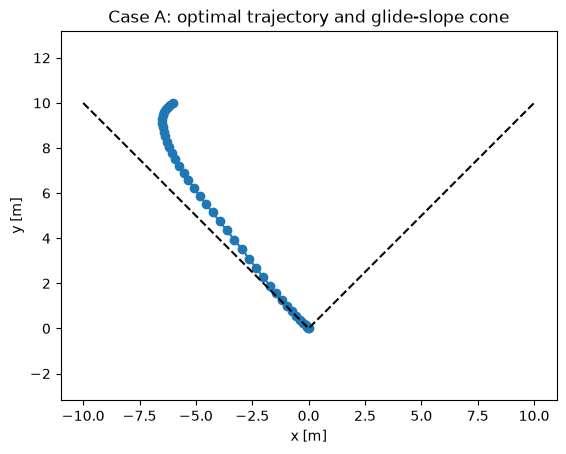

In [21]:
plt.plot(solA.p[:, 0], solA.p[:, 1], "o-")
plt.plot([-10, 0, 10], [10, 0, 10], "k--")   # 45deg cone
plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.axis("equal")
plt.title("Case A: optimal trajectory and glide-slope cone")
plt.show()

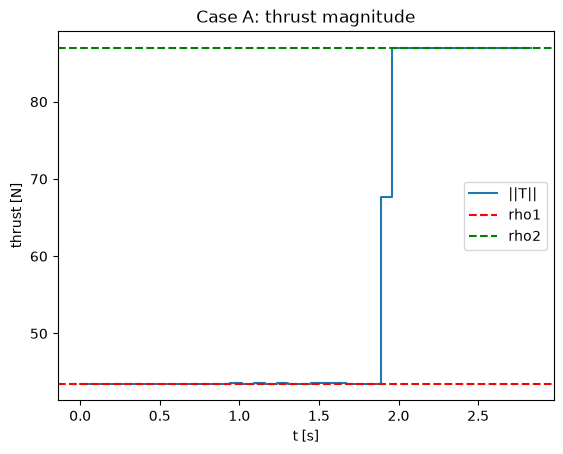

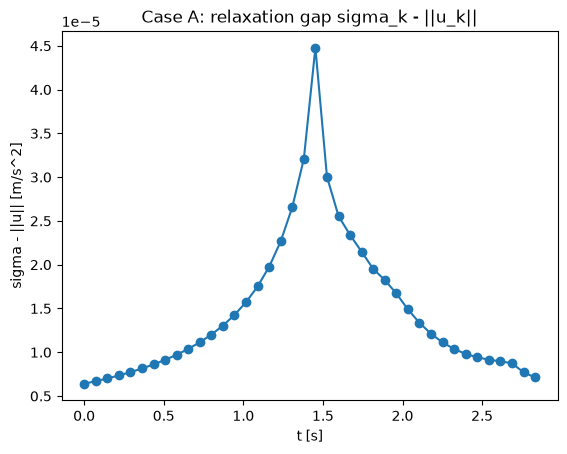

In [22]:
T = np.linalg.norm(solA.thrust, axis=1)
plt.step(solA.t[:-1], T, where="post", label="||T||")
plt.axhline(P.rho1, color="r", ls="--", label="rho1")
plt.axhline(P.rho2, color="g", ls="--", label="rho2")
plt.legend(); plt.xlabel("t [s]"); plt.ylabel("thrust [N]")
plt.title("Case A: thrust magnitude")
plt.show()

plt.plot(solA.t[:-1], solA.relaxation_gap, "o-")
plt.xlabel("t [s]"); plt.ylabel("sigma - ||u|| [m/s^2]")
plt.title("Case A: relaxation gap sigma_k - ||u_k||")
plt.show()

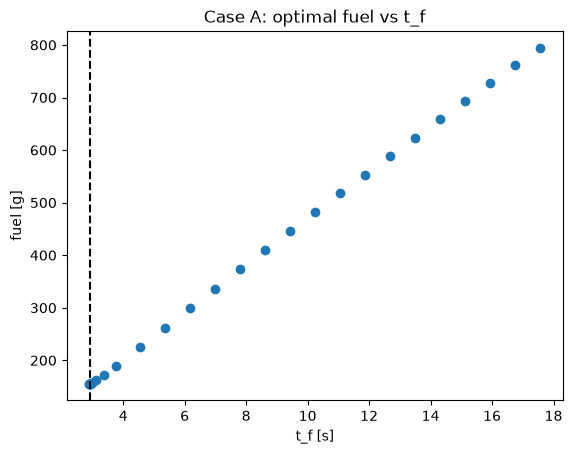

In [23]:
tf = [e[0] for e in evalsA if np.isfinite(e[1])]
fuel = [1000 * e[1] for e in evalsA if np.isfinite(e[1])]
plt.plot(tf, fuel, "o")
plt.axvline(solA.tgo, color="k", ls="--")
plt.xlabel("t_f [s]"); plt.ylabel("fuel [g]")
plt.title("Case A: optimal fuel vs t_f")
plt.show()

In [24]:
for mode in ["accel", "thrust"]:
    sim = simulate(solA, mode=mode)
    print(f"{mode:6s} | pos error = {100*sim['final_pos_err']:.3f} cm"
          f" | vel error = {100*sim['final_vel_err']:.3f} cm/s"
          f" | fuel = {1000*sim['fuel']:.1f} g")

accel  | pos error = 0.000 cm | vel error = 0.000 cm/s | fuel = 155.6 g
thrust | pos error = 1.212 cm | vel error = 1.295 cm/s | fuel = 155.6 g


In [25]:
# SLSQP on (P), 12 random starts, N=20, t_f = SOCP optimum
runs = nonconvex_baseline(x0A, solA.tgo, N=20, n_starts=12)

# SOCP with same N and t_f
prob20 = LanderSOCP(P, N=20)
prob20.solve(x0A, solA.tgo)               # first solve = compilation
t0 = time.perf_counter()
sol20 = prob20.solve(x0A, solA.tgo)
t_socp = time.perf_counter() - t0

print("run | converged | feasible | fuel (g) | time (s)")
for i, r in enumerate(runs):
    print(f"{i:3d} | {str(r['converged']):9s} | {str(r['feasible']):8s} | "
          f"{1000*r['fuel']:8.1f} | {r['time']:.2f}")

ok = [r for r in runs if r["feasible"]]
n_conv = sum(r["converged"] for r in runs)
fuels = [1000*r["fuel"] for r in ok]
print("\nmethod | fuel (g) | converged | feasible | time (s)")
print(f"SLSQP  | {min(fuels):.1f} - {max(fuels):.1f} | {n_conv}/12 | {len(ok)}/12 | "
      f"{np.mean([r['time'] for r in runs]):.2f} (mean)")
print(f"SOCP   | {1000*sol20.fuel:.1f} | 1/1 | 1/1 (certified: {is_lossless(sol20)}) | {t_socp:.4f}")

run | converged | feasible | fuel (g) | time (s)
  0 | True      | True     |    155.8 | 11.45
  1 | True      | True     |    156.3 | 15.24
  2 | True      | True     |    156.5 | 31.35
  3 | False     | True     |    156.4 | 38.58
  4 | True      | True     |    156.9 | 15.17
  5 | True      | True     |    156.8 | 31.58
  6 | True      | True     |    157.5 | 12.02
  7 | False     | True     |    156.7 | 41.00
  8 | True      | True     |    156.6 | 17.98
  9 | False     | True     |    156.3 | 40.91
 10 | True      | True     |    157.0 | 37.18
 11 | True      | True     |    156.9 | 29.56

method | fuel (g) | converged | feasible | time (s)
SLSQP  | 155.8 - 157.5 | 9/12 | 12/12 | 26.84 (mean)
SOCP   | 155.7 | 1/1 | 1/1 (certified: True) | 0.0090


### Question 3.2

In [26]:
x0B = np.array([-6., 9., -6., 0.])
m0B = P.m_dry + 0.17

# pad centre not reachable, even without the certificate
relaxed, _ = solve_min_fuel(LanderSOCP(P, N=40), x0B, m0B, certify=False)
print("Pad center reachable:", relaxed is not None)

solB, d_star, evalsB = solve_min_landing_error(P, x0B, m0B, N=40)
simB = simulate(solB, P, mode="accel")

print(f"d* (stage 1): {d_star:.4f} m")
print(f"t_f: {solB.tgo:.3f} s")
print(f"miss distance (stage 2): {solB.landing_error:.4f} m")
print(f"fuel used: {1000*solB.fuel:.1f} g, remaining: {1000*(0.17 - solB.fuel):.1f} g")
print(f"certified: {is_lossless(solB)}")
print(f"sim: pos error {100*simB['final_pos_err']:.3f} cm, speed {simB['final_vel_err']:.4f} m/s")
print(f"thrust violation: {simB['thrust_violation']:.4f} N, "
      f"glide-slope violation: {1000*glide_violation(simB['traj'], 1.):.2f} mm")

Pad center reachable: False
d* (stage 1): 2.4961 m
t_f: 3.649 s
miss distance (stage 2): 2.4971 m
fuel used: 170.0 g, remaining: 0.0 g
certified: True
sim: pos error 0.000 cm, speed 0.0000 m/s
thrust violation: 0.0339 N, glide-slope violation: 2.25 mm


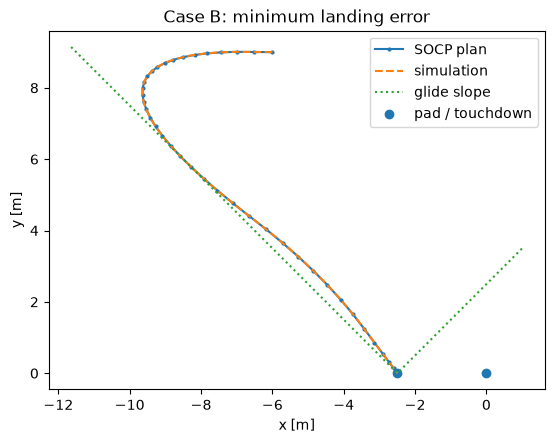

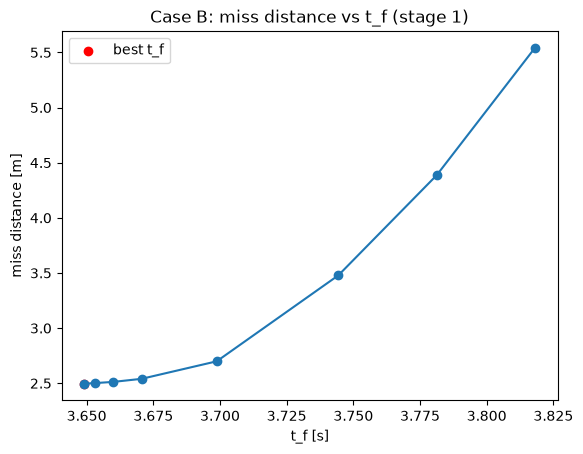

In [27]:
fig, ax = plt.subplots()
ax.plot(solB.p[:,0], solB.p[:,1], 'o-', markersize=2, label='SOCP plan')
ax.plot(simB['traj'][:,0], simB['traj'][:,1], '--', label='simulation')
xx = np.linspace(min(solB.p[:,0].min(), solB.p[-1,0]) - 2, max(0., solB.p[:,0].max()) + 1, 300)
ax.plot(xx, abs(xx - solB.p[-1,0]), ':', label='glide slope')
ax.scatter([0, solB.p[-1,0]], [0, 0], label='pad / touchdown')
ax.set(xlabel='x [m]', ylabel='y [m]', title='Case B: minimum landing error')
ax.set_aspect('equal'); ax.legend()
plt.show()

vals = np.asarray(evalsB); mask = np.isfinite(vals[:,1])
plt.plot(vals[mask,0], vals[mask,1], 'o-')
plt.scatter(solB.tgo, d_star, color='r', label='best t_f')
plt.xlabel('t_f [s]'); plt.ylabel('miss distance [m]'); plt.legend()
plt.title('Case B: miss distance vs t_f (stage 1)')
plt.show()

### Question 3.3

In [28]:
probB1 = LanderSOCP(P, N=40)

def make_guidance(certify):
    def guidance(x0, m0):
        sol, _ = solve_min_fuel(probB1, x0, m0, certify=certify)   # min fuel if reachable
        if sol is None:                                              # else min landing error (Q3.2)
            sol, _, _ = solve_min_landing_error(P, x0, m0, certify=certify)
        return sol
    return guidance

def d_star_fn(x0, m0):     # d* for the 3 unreachable cases
    _, d, _ = solve_min_landing_error(P, x0, m0)
    return d

In [29]:
# certify=False
rows_nc = run_b1(make_guidance(False), d_star_fn)

print("case | max gap  | landed | thrust below rho1 (N)")
for r in rows_nc:
    if r["ok"]:
        print(f"{r['case']:4d} | {r['gap']:.2e} | {str(r['landed']):6s} | {r['viol_T']:.3f}")
    else:
        print(f"{r['case']:4d} | no solution")

lossy = [r["case"] for r in rows_nc if r["ok"] and r["gap"] > 1e-3]
print("\nLossy cases:", lossy)

case | max gap  | landed | thrust below rho1 (N)
   0 | 2.47e-05 | True   | 0.019
   1 | 8.02e-01 | True   | 3.916
   2 | 6.79e-01 | True   | 3.421
   3 | 6.54e-01 | True   | 3.205
   4 | 1.14e+00 | True   | 5.840
   5 | 1.21e+00 | True   | 5.810
   6 | 8.08e-02 | True   | 0.432
   7 | 8.48e-01 | True   | 4.423
   8 | 1.12e+00 | True   | 5.756
   9 | 1.10e+00 | True   | 5.556
  10 | 1.04e+00 | True   | 5.263
  11 | 1.15e+00 | True   | 5.833
  12 | 1.08e+00 | True   | 5.517
  13 | 1.14e+00 | True   | 5.715
  14 | 3.27e-05 | True   | 0.022
  15 | 1.00e+00 | True   | 5.291
  16 | 1.10e+00 | True   | 5.715
  17 | 6.01e-01 | True   | 2.780
  18 | 2.83e-06 | True   | 0.029
  19 | 1.11e+00 | True   | 5.075

Lossy cases: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 19]


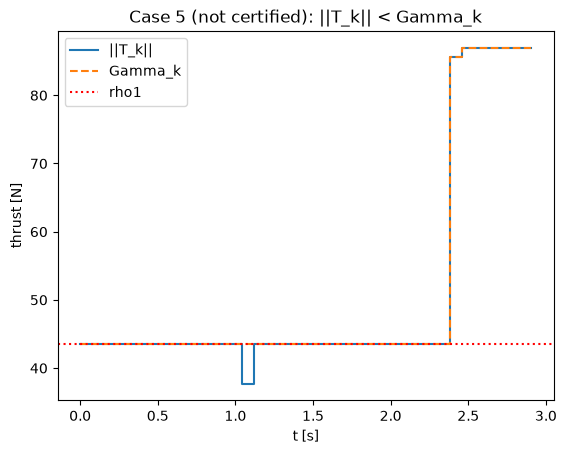

as planned : pos error 0.00 cm, speed 0.000 m/s, thrust below rho1 5.81 N
real engine: pos error 17.81 cm, speed 0.094 m/s


In [30]:
# most lossy case: planned thrust vs Gamma
c = max(lossy, key=lambda i: rows_nc[i]["gap"])
x0c, m0c = B1_CASES[c][:4], P.m_dry + B1_CASES[c][4]
solc = make_guidance(False)(x0c, m0c)

Tn = np.linalg.norm(solc.thrust, axis=1)
G = solc.sigma * np.exp(solc.z[:-1])
plt.step(solc.t[:-1], Tn, where="post", label="||T_k||")
plt.step(solc.t[:-1], G, where="post", ls="--", label="Gamma_k")
plt.axhline(P.rho1, color="r", ls=":", label="rho1")
plt.xlabel("t [s]"); plt.ylabel("thrust [N]"); plt.legend()
plt.title(f"Case {c} (not certified): ||T_k|| < Gamma_k")
plt.show()

# fly it with an engine that really gives ||T_k|| = Gamma_k (same direction)
u_real = solc.u * (solc.sigma / np.maximum(np.linalg.norm(solc.u, axis=1), 1e-9))[:, None]
sim_plan = simulate(solc)
sim_real = simulate(replace(solc, u=u_real))
print(f"as planned : pos error {100*sim_plan['final_pos_err']:.2f} cm, speed {sim_plan['final_vel_err']:.3f} m/s, "
      f"thrust below rho1 {sim_plan['thrust_violation']:.2f} N")
print(f"real engine: pos error {100*sim_real['final_pos_err']:.2f} cm, speed {sim_real['final_vel_err']:.3f} m/s")

In [31]:
# certify=True -> B1 summary table
rows = run_b1(make_guidance(True), d_star_fn)
df = pd.DataFrame(rows)
df["miss (cm)"] = 100 * df["d_land"]
df["d* (cm)"] = 100 * df["d_star"]
df["fuel (g)"] = 1000 * df["fuel"]
df["glide viol (mm)"] = 1000 * df["viol_gs"]
display(df[["case", "reachable", "landed", "miss (cm)", "d* (cm)", "fuel (g)",
            "viol_T", "glide viol (mm)", "gap", "t_solve"]]
        .round({"miss (cm)": 2, "d* (cm)": 1, "fuel (g)": 1, "viol_T": 3,
                "glide viol (mm)": 2, "gap": 5, "t_solve": 2}))
print(f"Landed: {df.landed.sum()}/20 | mean solve time: {df.t_solve.mean():.2f} s | "
      f"max thrust viol: {df.viol_T.max():.3f} N | max glide viol: {df['glide viol (mm)'].max():.2f} mm")

,case,reachable,landed,miss (cm),d* (cm),fuel (g),viol_T,glide viol (mm),gap,t_solve
0,0,True,True,0.00,NaN,131.8,0.019,0.00,0.00002,0.51
1,1,True,True,0.00,NaN,115.4,0.023,0.00,0.00064,0.38
2,2,True,True,0.00,NaN,123.9,0.023,0.00,0.00075,0.37
3,3,True,True,0.00,NaN,158.9,0.030,0.00,0.00036,0.34
4,4,True,True,0.00,NaN,137.5,0.025,0.00,0.00041,0.40
5,5,True,True,0.00,NaN,159.4,0.031,0.00,0.00070,0.37
6,6,True,True,0.00,NaN,165.4,0.032,0.00,0.00077,0.39
7,7,True,True,0.00,NaN,154.5,0.026,0.00,0.00027,0.35
8,8,True,True,0.00,NaN,131.9,0.023,0.00,0.00020,0.36
9,9,True,True,0.00,NaN,127.1,0.023,0.00,0.00053,0.37


Landed: 20/20 | mean solve time: 0.44 s | max thrust viol: 0.035 N | max glide viol: 2.09 mm


### Question 4

In [32]:
N_SEEDS = 100        # takes a while, use 10 to test
PROCESSES = 2

POLICIES = {
    "LCvx cascade": "lander.controllers:make_cascade",
    "Heuristic": "submissions/baseline_heuristic.py",
    "PPO": "submissions/baseline_ppo.py",
}
CONDITIONS = ("nominal", "heavy", "light", "gusty", "storm")

In [33]:
summaries = {}
with tempfile.TemporaryDirectory() as tmp:
    for name, source in POLICIES.items():
        result = Path(tmp) / f"{name.replace(' ', '_')}.json"
        cmd = [sys.executable, "-m", "lander.evaluate", "--policy", source,
               "--benchmark", "b2", "--n", str(N_SEEDS),
               "--processes", str(PROCESSES), "--out", str(result)]
        print(f"=== {name} ({N_SEEDS} seeds / condition) ===", flush=True)
        run = subprocess.run(cmd, capture_output=True, text=True)
        print(run.stdout[-1500:])
        if run.returncode != 0:
            print(run.stderr[-3000:])
            raise RuntimeError(f"{name} failed")
        summaries[name] = json.loads(result.read_text())["summary"]

=== LCvx cascade (100 seeds / condition) ===
{
 "score": 86.7167931234604,
 "n": 500,
 "success": 0.99,
 "off_pad": 0.01,
 "hazard": 0.0,
 "crash": 0.0,
 "hard": 0.0,
 "out": 0.0,
 "timeout": 0.0,
 "fuel_success": 2.4952096451459047,
 "vy_success": 1.162449174697953,
 "policy_ms": 1.0669600981856142
}
nominal : score    88.0  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.40  ms 1.0
heavy   : score    86.8  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.63  ms 1.3
light   : score    88.4  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.32  ms 1.1
gusty   : score    85.4  success 0.97  hazard 0.00  crash 0.00  off_pad 0.03  out 0.00  timeout 0.00  fuel 2.42  ms 1.0
storm   : score    84.9  success 0.98  hazard 0.00  crash 0.00  off_pad 0.02  out 0.00  timeout 0.00  fuel 2.69  ms 0.9

=== Heuristic (100 seeds / condition) ===
{
 "score": 71.50148525035381,
 "n": 500,
 "success": 

In [34]:
def num(x):
    return x if math.isfinite(x) else float("nan")

overall = pd.DataFrame([{
    "Policy": name,
    "Success (%)": 100 * s["overall"]["success"],
    "Mean score": num(s["overall"]["score"]),
    "Fuel (s, successes)": num(s["overall"]["fuel_success"]),
    "Time (ms/step)": num(s["overall"]["policy_ms"]),
} for name, s in summaries.items()])
display(overall.round(2))

,Policy,Success (%),Mean score,"Fuel (s, successes)",Time (ms/step)
0,LCvx cascade,99.0,86.72,2.50,1.07
1,Heuristic,78.2,71.50,1.79,0.02
2,PPO,69.6,58.53,3.41,0.66


In [35]:
rows = []
for c in CONDITIONS:
    for name, s in summaries.items():
        a = s["per_scenario"][c]
        rows.append({
            "Environment": c, "Policy": name,
            "Success (%)": 100 * a["success"],
            "Fuel (s, successes)": num(a["fuel_success"]),
            "Time (ms/step)": num(a["policy_ms"]),
            "Off-pad (%)": 100 * a["off_pad"],
            "Crash/hard (%)": 100 * (a["crash"] + a["hard"]),
        })
display(pd.DataFrame(rows).round(2))

,Environment,Policy,Success (%),"Fuel (s, successes)",Time (ms/step),Off-pad (%),Crash/hard (%)
0,nominal,LCvx cascade,100.0,2.40,0.98,0.0,0.0
1,nominal,Heuristic,96.0,1.77,0.02,4.0,0.0
2,nominal,PPO,93.0,3.33,0.65,5.0,0.0
3,heavy,LCvx cascade,100.0,2.63,1.28,0.0,0.0
4,heavy,Heuristic,48.0,1.76,0.02,19.0,33.0
5,heavy,PPO,82.0,2.87,0.65,16.0,0.0
6,light,LCvx cascade,100.0,2.32,1.15,0.0,0.0
7,light,Heuristic,96.0,1.34,0.02,4.0,0.0
8,light,PPO,100.0,3.97,0.70,0.0,0.0
9,gusty,LCvx cascade,97.0,2.42,1.00,3.0,0.0


### Question 4

In [36]:
N_SEEDS = 10        # 100 for the final report
PROCESSES = 2

POLICIES = {
    "LCvx cascade": "lander.controllers:make_cascade",
    "Heuristic": "submissions/baseline_heuristic.py",
    "PPO": "submissions/baseline_ppo.py",
}
CONDITIONS = ("nominal", "heavy", "light", "gusty", "storm")

In [37]:
summaries = {}
with tempfile.TemporaryDirectory() as tmp:
    for name, source in POLICIES.items():
        result = Path(tmp) / f"{name.replace(' ', '_')}.json"
        cmd = [sys.executable, "-m", "lander.evaluate", "--policy", source,
               "--benchmark", "b2", "--n", str(N_SEEDS),
               "--processes", str(PROCESSES), "--out", str(result)]
        print(f"=== {name} ({N_SEEDS} seeds / condition) ===", flush=True)
        run = subprocess.run(cmd, capture_output=True, text=True)
        print(run.stdout[-1500:])                          # last lines of the evaluator output
        if run.returncode != 0:
            print(run.stderr[-3000:])
            raise RuntimeError(f"{name} failed")
        summaries[name] = json.loads(result.read_text())["summary"]

=== LCvx cascade (10 seeds / condition) ===
{
 "score": 87.69848817556098,
 "n": 50,
 "success": 1.0,
 "off_pad": 0.0,
 "hazard": 0.0,
 "crash": 0.0,
 "hard": 0.0,
 "out": 0.0,
 "timeout": 0.0,
 "fuel_success": 2.4603023648878035,
 "vy_success": 1.145518229007721,
 "policy_ms": 1.0884864932561626
}
nominal : score    86.3  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.74  ms 1.0
heavy   : score    87.0  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.59  ms 1.3
light   : score    90.7  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 1.86  ms 1.2
gusty   : score    88.3  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.33  ms 1.0
storm   : score    86.1  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.78  ms 0.9

=== Heuristic (10 seeds / condition) ===
{
 "score": 72.72696239054203,
 "n": 50,
 "success": 0.8,


In [38]:
def num(x):
    return x if math.isfinite(x) else float("nan")

overall = pd.DataFrame([{
    "Policy": name,
    "Success (%)": 100 * s["overall"]["success"],
    "Mean score": num(s["overall"]["score"]),
    "Fuel (s, successes)": num(s["overall"]["fuel_success"]),
    "Time (ms/step)": num(s["overall"]["policy_ms"]),
} for name, s in summaries.items()])
display(overall.round(2))

,Policy,Success (%),Mean score,"Fuel (s, successes)",Time (ms/step)
0,LCvx cascade,100.0,87.70,2.46,1.09
1,Heuristic,80.0,72.73,1.89,0.02
2,PPO,76.0,64.35,3.34,1.13


In [39]:
rows = []
for c in CONDITIONS:
    for name, s in summaries.items():
        a = s["per_scenario"][c]
        rows.append({
            "Environment": c, "Policy": name,
            "Success (%)": 100 * a["success"],
            "Fuel (s, successes)": num(a["fuel_success"]),
            "Time (ms/step)": num(a["policy_ms"]),
            "Off-pad (%)": 100 * a["off_pad"],
            "Crash/hard (%)": 100 * (a["crash"] + a["hard"]),
        })
display(pd.DataFrame(rows).round(2))

,Environment,Policy,Success (%),"Fuel (s, successes)",Time (ms/step),Off-pad (%),Crash/hard (%)
0,nominal,LCvx cascade,100.0,2.74,0.99,0.0,0.0
1,nominal,Heuristic,90.0,1.87,0.02,10.0,0.0
2,nominal,PPO,100.0,3.31,1.21,0.0,0.0
3,heavy,LCvx cascade,100.0,2.59,1.26,0.0,0.0
4,heavy,Heuristic,70.0,1.76,0.02,0.0,30.0
5,heavy,PPO,90.0,2.83,1.04,10.0,0.0
6,light,LCvx cascade,100.0,1.86,1.24,0.0,0.0
7,light,Heuristic,100.0,1.45,0.03,0.0,0.0
8,light,PPO,100.0,3.84,1.19,0.0,0.0
9,gusty,LCvx cascade,100.0,2.33,1.01,0.0,0.0
